In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import scipy.cluster.hierarchy as sch

In [2]:
# Set visual aesthetic
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
# 1. DATA LOADING & CLEANING
# ==========================================
file_path = 'P706_ World_development_mesurement.xlsx'
df = pd.read_excel(file_path)

print(f"Dataset Loaded. Initial Shape: {df.shape}")

# Clean monetary and percentage string columns
money_cols = ['GDP', 'Health Exp/Capita', 'Tourism Inbound', 'Tourism Outbound', 'Business Tax Rate']
for col in money_cols:
    if df[col].dtype == object:
        df[col] = df[col].astype(str).str.replace('$', '', regex=False)\
                                  .str.replace(',', '', regex=False)\
                                  .str.replace('%', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop redundant or non-informative columns
df = df.drop(columns=['Ease of Business', 'Number of Records'], errors='ignore')

Dataset Loaded. Initial Shape: (2704, 25)


In [4]:
# 2. AGGREGATION & FEATURE ENGINEERING
# Aggregate repeated annual records per country to get historical averages
country_df = df.groupby('Country').mean(numeric_only=True)

In [5]:
# Calculate Per Capita (per person) Metrics
pop = country_df['Population Total']
country_df['GDP_per_Capita'] = country_df['GDP'] / pop
country_df['CO2_per_Capita'] = country_df['CO2 Emissions'] / pop
country_df['Energy_per_Capita'] = country_df['Energy Usage'] / pop
country_df['Tourism_Inbound_per_Capita'] = country_df['Tourism Inbound'] / pop
country_df['Tourism_Outbound_per_Capita'] = country_df['Tourism Outbound'] / pop

In [6]:
# Define cluster feature set (exclude raw total scale metrics)
raw_totals = ['GDP', 'CO2 Emissions', 'Energy Usage', 'Tourism Inbound', 'Tourism Outbound', 'Population Total']
cluster_features = [col for col in country_df.columns if col not in raw_totals]

X = country_df[cluster_features].copy()

In [7]:
# Impute missing values using column medians (robust against outliers)
X_imputed = X.fillna(X.median())



In [8]:
# Scale features to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=cluster_features, index=X.index)

In [9]:
# 3. OPTIMAL K DETERMINATION (ELBOW & SILHOUETTE)
# ==========================================
inertia = []
silhouette_vals = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette_vals.append(silhouette_score(X_scaled, labels))

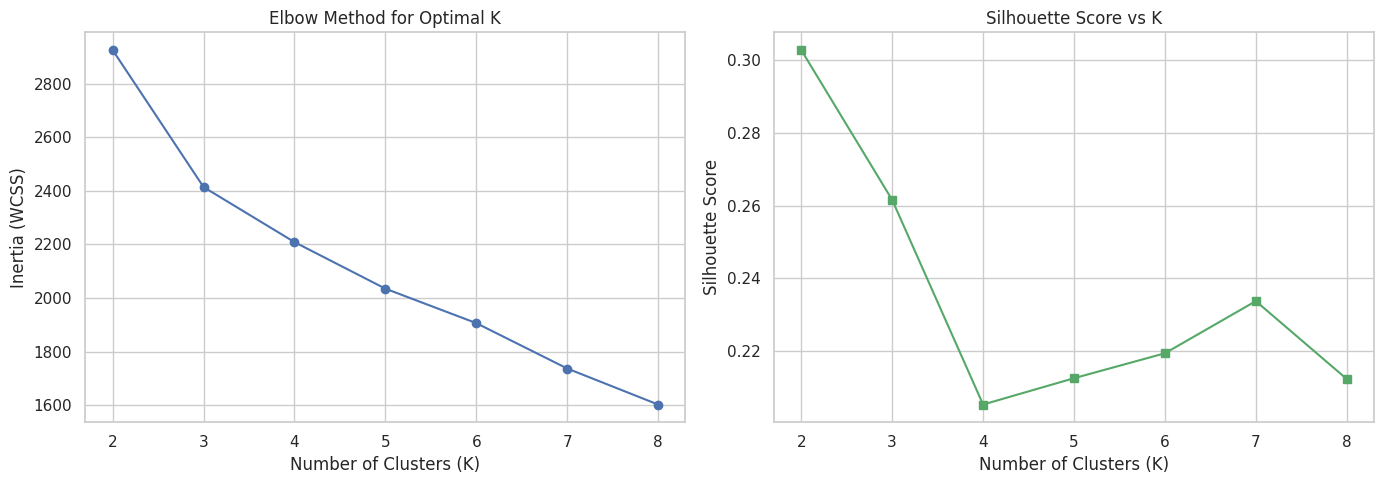

In [10]:
# Plot Elbow Method & Silhouette Scores
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(K_range, inertia, marker='o', color='b')
ax[0].set_title('Elbow Method for Optimal K')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('Inertia (WCSS)')

ax[1].plot(K_range, silhouette_vals, marker='s', color='g')
ax[1].set_title('Silhouette Score vs K')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

In [11]:
# 4. MODEL BUILDING & COMPARATIVE ANALYSIS

optimal_k = 3

# Model 1: K-Means
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)

In [12]:
# Model 2: Hierarchical Clustering (Agglomerative)
hc = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)

In [13]:
# Model 3: DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)

In [14]:
# Comparative Metric Evaluation Table
comparison_metrics = [
    {
        'Algorithm': 'K-Means',
        'Clusters Found': len(set(km_labels)),
        'Silhouette Score': round(silhouette_score(X_scaled, km_labels), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(X_scaled, km_labels), 4)
    },
    {
        'Algorithm': 'Hierarchical Clustering',
        'Clusters Found': len(set(hc_labels)),
        'Silhouette Score': round(silhouette_score(X_scaled, hc_labels), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(X_scaled, hc_labels), 4)
    },
    {
        'Algorithm': 'DBSCAN',
        'Clusters Found': len(set(db_labels) - {-1}),
        'Silhouette Score': round(silhouette_score(X_scaled, db_labels), 4) if len(set(db_labels)) > 1 else 'N/A',
        'Davies-Bouldin Index': round(davies_bouldin_score(X_scaled, db_labels), 4) if len(set(db_labels)) > 1 else 'N/A'
    }
]

comparison_df = pd.DataFrame(comparison_metrics)
print("\n--- MODEL COMPARATIVE ANALYSIS ---")
print(comparison_df.to_string(index=False))


--- MODEL COMPARATIVE ANALYSIS ---
              Algorithm  Clusters Found  Silhouette Score  Davies-Bouldin Index
                K-Means               3            0.2616                1.3880
Hierarchical Clustering               3            0.2352                1.3836
                 DBSCAN               2            0.1422                3.4996


In [15]:
# 5. BUSINESS PROFILING (K-MEANS)
# ==========================================
country_df['Cluster'] = km_labels

cluster_profile = country_df.groupby('Cluster')[['GDP_per_Capita', 'Health Exp/Capita',
                                                'CO2_per_Capita', 'Life Expectancy Female',
                                                'Infant Mortality Rate', 'Internet Usage']].mean()

print("\n--- CLUSTER BUSINESS PROFILES (MEANS) ---")
print(cluster_profile.T.round(2))


--- CLUSTER BUSINESS PROFILES (MEANS) ---
Cluster                        0        1        2
GDP_per_Capita          39539.63  1343.68  7012.55
Health Exp/Capita        2942.46    66.80   356.27
CO2_per_Capita              0.01     0.00     0.00
Life Expectancy Female     81.45    58.89    75.73
Infant Mortality Rate       0.01     0.07     0.02
Internet Usage              0.56     0.03     0.23


In [16]:
import joblib

# 1. Save the trained KMeans model and the StandardScaler to files
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Model and Scaler successfully saved for deployment!")



Model and Scaler successfully saved for deployment!


In [17]:
# 2. Write a quick prediction function for a new country (Inference)
def predict_country_cluster(country_features_dict):
    # Convert input dictionary to a DataFrame
    input_df = pd.DataFrame([country_features_dict])

    # Scale the input using the saved/fitted scaler
    input_scaled = scaler.transform(input_df)

    # Predict the cluster
    cluster_id = kmeans.predict(input_scaled)[0]
    return f"This country belongs to Cluster {cluster_id}"

# Example test: (Using the feature names from your dataset)
# sample_country = {'GDP_per_Capita': 45000, 'Health Exp/Capita': 3500, 'Life Expectancy Female': 80, ...}
# print(predict_country_cluster(sample_country))